In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Loading Quotation Dataset

In [5]:
bike_q= pd.read_csv(r"C:\projects\acko_insurance_ai_platform\data\raw\acko_bike_quotation.csv")
car_q= pd.read_csv(r"C:\projects\acko_insurance_ai_platform\data\raw\acko_car_quotation.csv")

In [6]:
bike_q.head()

,record_id,customer_age,city,state,city_tier,city_risk_score,vehicle_make,vehicle_model,variant,segment,...,policy_type,usage_type,num_addons,addons_list,od_premium_before_ncb,ncb_discount_amount,tp_premium,addon_premium,gst_amount,annual_premium
0,c007100c,60,Rajahmundry,Andhra Pradesh,3,0.88,Royal Enfield,Bullet 500,STD,retro,...,Comprehensive,Personal,0,NaN,3861.87,0.00,2804,0.00,1295.85,8338
1,01557b26,21,Indore,Madhya Pradesh,2,1.15,Yamaha,Fascino 125,ABS,scooter,...,Third Party,Personal,0,NaN,1139.68,512.86,714,0.00,151.65,1035
2,656c8f49,19,Patna,Bihar,2,1.20,Suzuki,Gixxer 150,Drum,sport,...,Third Party,Personal,3,"Roadside Assistance, Consumables Cover, Return...",2464.40,862.54,1366,3317.48,290.14,1829
3,506ccfca,20,Muzaffarpur,Bihar,3,0.88,Bounce,Infinity E1,ABS,ev_scooter,...,Comprehensive,Personal,0,NaN,702.02,315.91,687,0.00,227.93,1536
4,3d46cd32,19,Karnal,Haryana,3,0.90,Honda,CB Hornet 2.0,Limited Edition,sport,...,Own Damage,Personal,0,NaN,2164.95,974.23,1366,0.00,252.91,1731


In [7]:
bike_q['vehicle_type'] = "bike"

In [8]:
bike_q.shape

(150000, 29)

In [9]:
car_q.head()

,record_id,customer_age,city,state,city_tier,city_risk_score,vehicle_make,vehicle_model,variant,segment,...,policy_type,previous_insurer,num_addons,addons_list,od_premium_before_ncb,ncb_discount_amount,tp_premium,addon_premium,gst_amount,annual_premium
0,d96cac39,26,Kolkata,West Bengal,1,1.40,Honda,Amaze,Deluxe,sedan,...,Third Party,Tata AIG,0,NaN,13543.01,6771.51,3416,0.00,614.88,4212
1,8a5e47cd,59,Panaji,Goa,3,0.95,Mercedes-Benz,A-Class Limousine,Sport,sedan,...,Comprehensive,Acko,3,"Personal Accident Cover, Return to Invoice, Ke...",133631.52,66815.76,3416,3192.95,14419.13,95457
2,653b7fa5,40,Bhopal,Madhya Pradesh,2,1.12,Nissan,Magnite,Turbo,suv,...,Third Party,Reliance General,4,"Personal Accident Cover, Roadside Assistance, ...",11130.53,2782.63,2094,7474.75,376.92,2385
3,b3ec92ca,32,Madurai,Tamil Nadu,2,1.10,Ford,Aspire,Long Range,sedan,...,Third Party,Tata AIG,1,Return to Invoice,10674.04,2668.51,3416,1076.51,614.88,4178
4,43ef7ada,61,Thiruvananthapuram,Kerala,3,1.00,Ford,Aspire,Deluxe,sedan,...,Comprehensive,Bajaj Allianz,1,Consumables Cover,9590.42,4795.21,3416,1173.35,1858.14,12434


In [10]:
car_q['vehicle_type'] = "car"

In [11]:
car_q.shape

(200000, 29)

In [12]:
bike_q.columns

Index(['record_id', 'customer_age', 'city', 'state', 'city_tier',
       'city_risk_score', 'vehicle_make', 'vehicle_model', 'variant',
       'segment', 'fuel_type', 'colour', 'manufacturing_year',
       'vehicle_age_years', 'engine_cc', 'idv', 'ncb_percent',
       'claim_history_count', 'policy_type', 'usage_type', 'num_addons',
       'addons_list', 'od_premium_before_ncb', 'ncb_discount_amount',
       'tp_premium', 'addon_premium', 'gst_amount', 'annual_premium',
       'vehicle_type'],
      dtype='object')

In [13]:
car_q.columns

Index(['record_id', 'customer_age', 'city', 'state', 'city_tier',
       'city_risk_score', 'vehicle_make', 'vehicle_model', 'variant',
       'segment', 'fuel_type', 'colour', 'manufacturing_year',
       'vehicle_age_years', 'engine_cc', 'idv', 'ncb_percent',
       'claim_history_count', 'policy_type', 'previous_insurer', 'num_addons',
       'addons_list', 'od_premium_before_ncb', 'ncb_discount_amount',
       'tp_premium', 'addon_premium', 'gst_amount', 'annual_premium',
       'vehicle_type'],
      dtype='object')

### Combining Datasets

In [14]:
combined_df= pd.concat([bike_q, car_q], ignore_index=True)

In [15]:
combined_df.sample(5)

,record_id,customer_age,city,state,city_tier,city_risk_score,vehicle_make,vehicle_model,variant,segment,...,num_addons,addons_list,od_premium_before_ncb,ncb_discount_amount,tp_premium,addon_premium,gst_amount,annual_premium,vehicle_type,previous_insurer
162158,d3a19919,43,Pimpri-Chinchwad,Maharashtra,2,1.18,Skoda,Kushaq,Deluxe,suv,...,0,NaN,23066.23,4613.25,2094,0.00,3698.46,23314,car,Acko
1316,29b2f361,39,Guntur,Andhra Pradesh,2,1.05,Honda,Shine 100,Pro,commuter,...,1,Consumables Cover,2364.70,1182.35,714,1146.87,564.80,3518,bike,NaN
7614,f62ec3c1,60,Karnal,Haryana,3,0.90,Ola Electric,S1 Air,Limited Edition,ev_scooter,...,2,"Roadside Assistance, Zero Depreciation",980.75,0.00,687,1490.78,133.55,861,bike,NaN
126652,4b738eb4,36,Agra,Uttar Pradesh,2,1.18,Ola Electric,S1 X+,Limited Edition,ev_scooter,...,1,Roadside Assistance,2329.15,465.83,687,1079.65,529.74,3435,bike,NaN
46180,427f9612,63,Vadodara,Gujarat,2,1.12,Ola Electric,S1 Z,Double Disc,ev_scooter,...,0,NaN,1448.71,289.74,687,0.00,133.55,894,bike,NaN


In [16]:
combined_df.shape

(350000, 30)

In [17]:
combined_df.isnull().sum()

record_id                     0
customer_age                  0
city                          0
state                         0
city_tier                     0
city_risk_score               0
vehicle_make                  0
vehicle_model                 0
variant                       0
segment                       0
fuel_type                     0
colour                        0
manufacturing_year            0
vehicle_age_years             0
engine_cc                     0
idv                           0
ncb_percent                   0
claim_history_count           0
policy_type                   0
usage_type               200000
num_addons                    0
addons_list              110313
od_premium_before_ncb         0
ncb_discount_amount           0
tp_premium                    0
addon_premium                 0
gst_amount                    0
annual_premium                0
vehicle_type                  0
previous_insurer         172121
dtype: int64

In [18]:
combined_df.columns

Index(['record_id', 'customer_age', 'city', 'state', 'city_tier',
       'city_risk_score', 'vehicle_make', 'vehicle_model', 'variant',
       'segment', 'fuel_type', 'colour', 'manufacturing_year',
       'vehicle_age_years', 'engine_cc', 'idv', 'ncb_percent',
       'claim_history_count', 'policy_type', 'usage_type', 'num_addons',
       'addons_list', 'od_premium_before_ncb', 'ncb_discount_amount',
       'tp_premium', 'addon_premium', 'gst_amount', 'annual_premium',
       'vehicle_type', 'previous_insurer'],
      dtype='object')

### Handling null values

In [19]:
combined_df.loc[(combined_df['vehicle_type'] == 'bike') & (combined_df['previous_insurer'].isnull()), 'previous_insurer'] = "Not available"
combined_df.loc[(combined_df['vehicle_type'] == 'car') & (combined_df['previous_insurer'].isnull()), 'previous_insurer'] = "First time buyer"

In [20]:
combined_df.shape

(350000, 30)

In [21]:
combined_df.isna().sum()

record_id                     0
customer_age                  0
city                          0
state                         0
city_tier                     0
city_risk_score               0
vehicle_make                  0
vehicle_model                 0
variant                       0
segment                       0
fuel_type                     0
colour                        0
manufacturing_year            0
vehicle_age_years             0
engine_cc                     0
idv                           0
ncb_percent                   0
claim_history_count           0
policy_type                   0
usage_type               200000
num_addons                    0
addons_list              110313
od_premium_before_ncb         0
ncb_discount_amount           0
tp_premium                    0
addon_premium                 0
gst_amount                    0
annual_premium                0
vehicle_type                  0
previous_insurer              0
dtype: int64

In [22]:
combined_df['usage_type'].isna().sum()

np.int64(200000)

In [23]:
combined_df.loc[(combined_df['vehicle_type']== 'car') & (combined_df['usage_type'].isnull()), "usage_type"] = "Not available"

In [24]:
combined_df.isna().sum()

record_id                     0
customer_age                  0
city                          0
state                         0
city_tier                     0
city_risk_score               0
vehicle_make                  0
vehicle_model                 0
variant                       0
segment                       0
fuel_type                     0
colour                        0
manufacturing_year            0
vehicle_age_years             0
engine_cc                     0
idv                           0
ncb_percent                   0
claim_history_count           0
policy_type                   0
usage_type                    0
num_addons                    0
addons_list              110313
od_premium_before_ncb         0
ncb_discount_amount           0
tp_premium                    0
addon_premium                 0
gst_amount                    0
annual_premium                0
vehicle_type                  0
previous_insurer              0
dtype: int64

In [25]:
combined_df['addons_list'].value_counts()

addons_list
Engine Protection                                                                 14805
Roadside Assistance                                                               14744
Zero Depreciation                                                                 14672
Consumables Cover                                                                 14669
Return to Invoice                                                                 14657
                                                                                  ...  
Consumables Cover, Personal Accident Cover, Passenger Cover, Tyre Protection          1
Zero Depreciation, Tyre Protection, Passenger Cover, No Claim Bonus Protection        1
Return to Invoice, Passenger Cover, Personal Accident Cover, Tyre Protection          1
Return to Invoice, Passenger Cover, Key Replacement, Zero Depreciation                1
Tyre Protection, Return to Invoice, Passenger Cover, Consumables Cover                1
Name: count, Length:

In [26]:
combined_df[combined_df['addons_list'] == 'None'].shape[0]

0

In [27]:
combined_df['addons_list'] = combined_df['addons_list'].fillna("No addons")

In [28]:
combined_df.isna().sum()

record_id                0
customer_age             0
city                     0
state                    0
city_tier                0
city_risk_score          0
vehicle_make             0
vehicle_model            0
variant                  0
segment                  0
fuel_type                0
colour                   0
manufacturing_year       0
vehicle_age_years        0
engine_cc                0
idv                      0
ncb_percent              0
claim_history_count      0
policy_type              0
usage_type               0
num_addons               0
addons_list              0
od_premium_before_ncb    0
ncb_discount_amount      0
tp_premium               0
addon_premium            0
gst_amount               0
annual_premium           0
vehicle_type             0
previous_insurer         0
dtype: int64

In [29]:
combined_df['addons_list'].value_counts()

addons_list
No addons                                                                                     110313
Engine Protection                                                                              14805
Roadside Assistance                                                                            14744
Zero Depreciation                                                                              14672
Consumables Cover                                                                              14669
                                                                                               ...  
Roadside Assistance, Tyre Protection, No Claim Bonus Protection, Passenger Cover                   1
Personal Accident Cover, Return to Invoice, No Claim Bonus Protection, Roadside Assistance         1
Roadside Assistance, Personal Accident Cover, Engine Protection, Consumables Cover                 1
Roadside Assistance, Zero Depreciation, Tyre Protection, Personal Accident Cove

In [30]:
combined_df['addons_list'] = combined_df['addons_list'].str.split(",")

In [31]:
combined_df['addons_list']= combined_df['addons_list'].apply(lambda  x : [item.strip() for item in x])

In [32]:
# dropping columns

In [33]:
combined_df= combined_df.drop(['engine_cc', 'od_premium_before_ncb', 'ncb_discount_amount', 'tp_premium', 'addon_premium', 'gst_amount'], axis=1)

In [34]:
combined_df= combined_df.drop('record_id', axis=1)

In [35]:
combined_df.shape

(350000, 23)

In [33]:
# splitting into categorical and numerical columns

In [36]:
cat_cols_ohe= combined_df.select_dtypes(include= ['object']).drop(columns=["addons_list"])

In [37]:
cat_cols_mlb= combined_df['addons_list']

In [38]:
num_cols= combined_df.select_dtypes(exclude=['object'])

### Univariate Analysis

In [37]:
# nums_cols

In [39]:
num_cols.describe()

,customer_age,city_tier,city_risk_score,manufacturing_year,vehicle_age_years,idv,ncb_percent,claim_history_count,num_addons,annual_premium
count,350000.000000,350000.000000,350000.000000,350000.000000,350000.000000,3.500000e+05,350000.000000,350000.000000,350000.000000,3.500000e+05
mean,44.369377,2.434874,1.031304,2014.503731,10.496269,9.116494e+05,29.172000,0.791937,1.222489,3.209524e+04
std,15.769647,0.618888,0.160425,5.768238,5.768238,1.771243e+06,16.677121,1.010399,1.098265,6.601351e+04
min,18.000000,1.000000,0.820000,2005.000000,1.000000,1.500000e+04,0.000000,0.000000,0.000000,5.380000e+02
25%,31.000000,2.000000,0.900000,2009.000000,5.000000,6.591500e+04,20.000000,0.000000,0.000000,3.061000e+03
50%,44.000000,3.000000,1.000000,2014.000000,11.000000,2.887250e+05,35.000000,0.000000,1.000000,9.541000e+03
75%,57.000000,3.000000,1.120000,2020.000000,16.000000,9.220350e+05,45.000000,1.000000,2.000000,2.960425e+04
max,75.000000,3.000000,1.500000,2024.000000,20.000000,2.373989e+07,50.000000,4.000000,4.000000,1.607449e+06


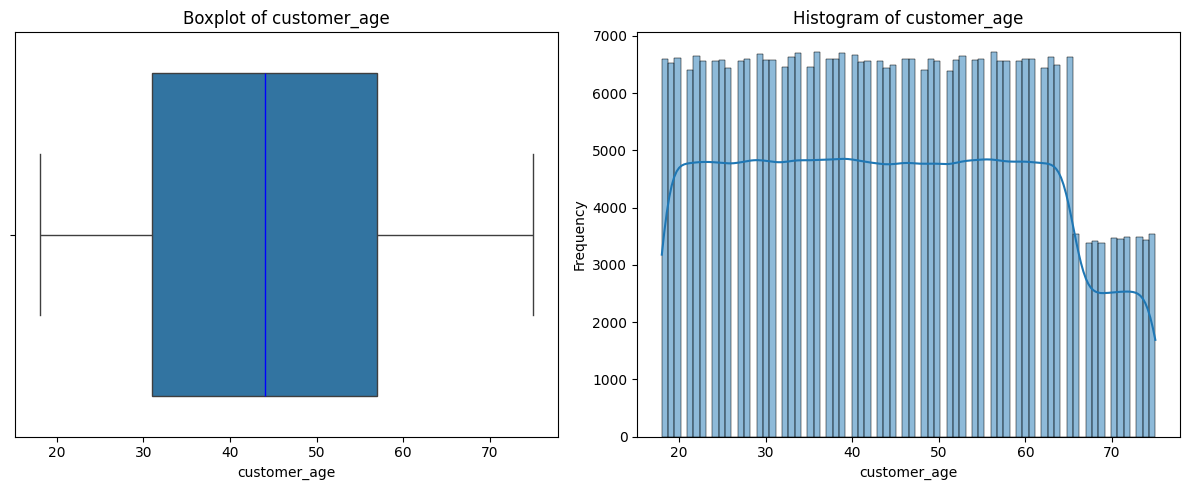

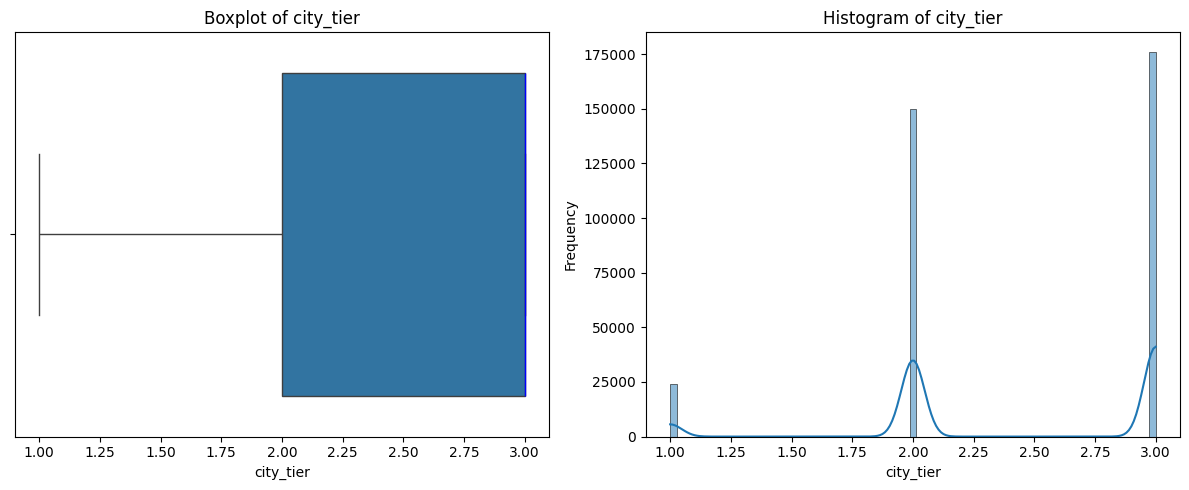

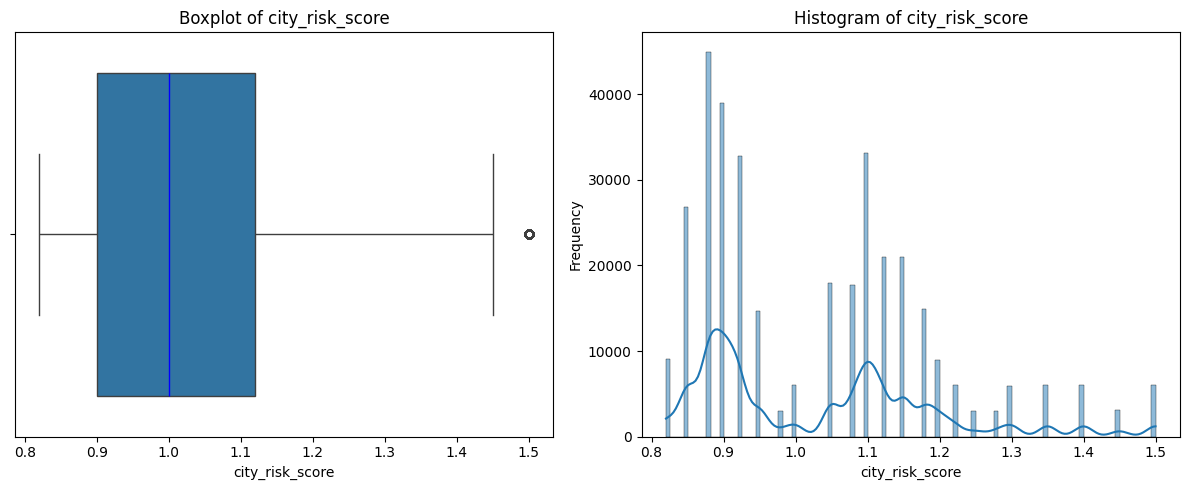

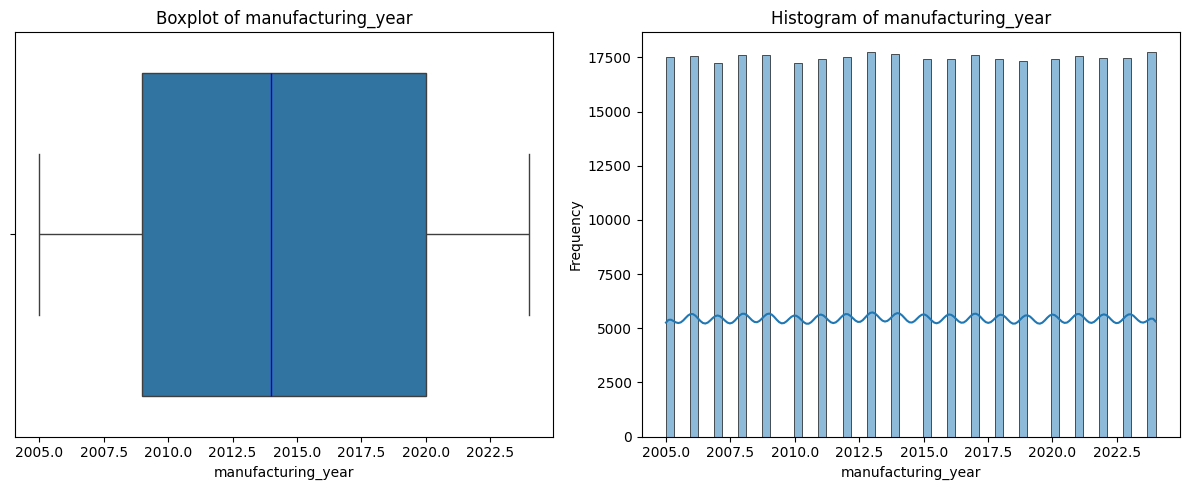

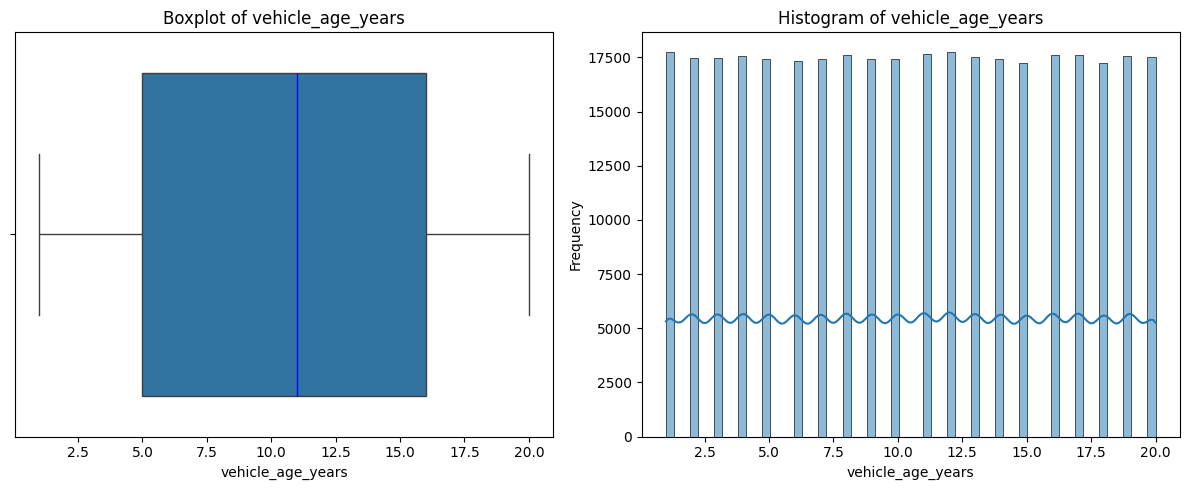

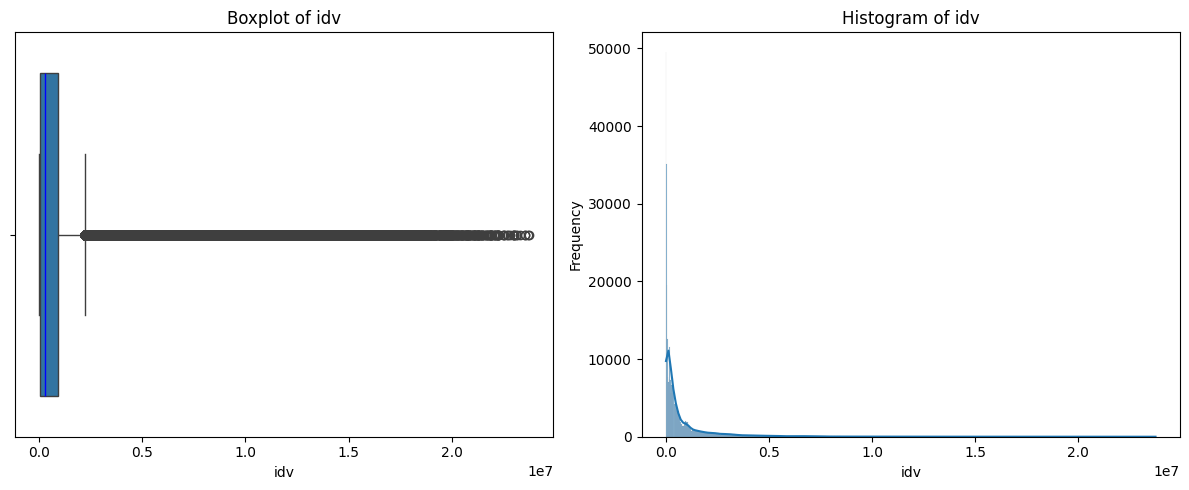

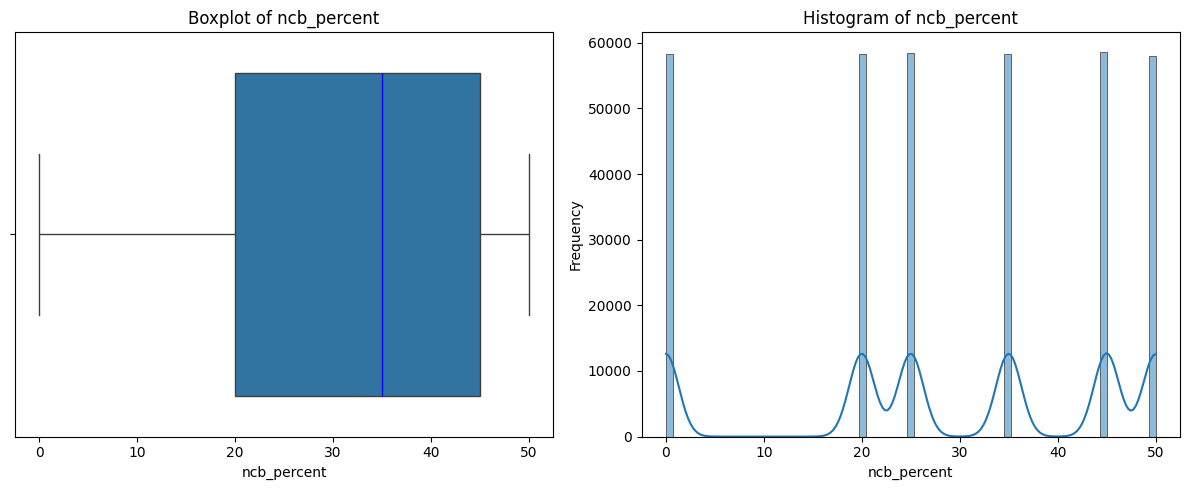

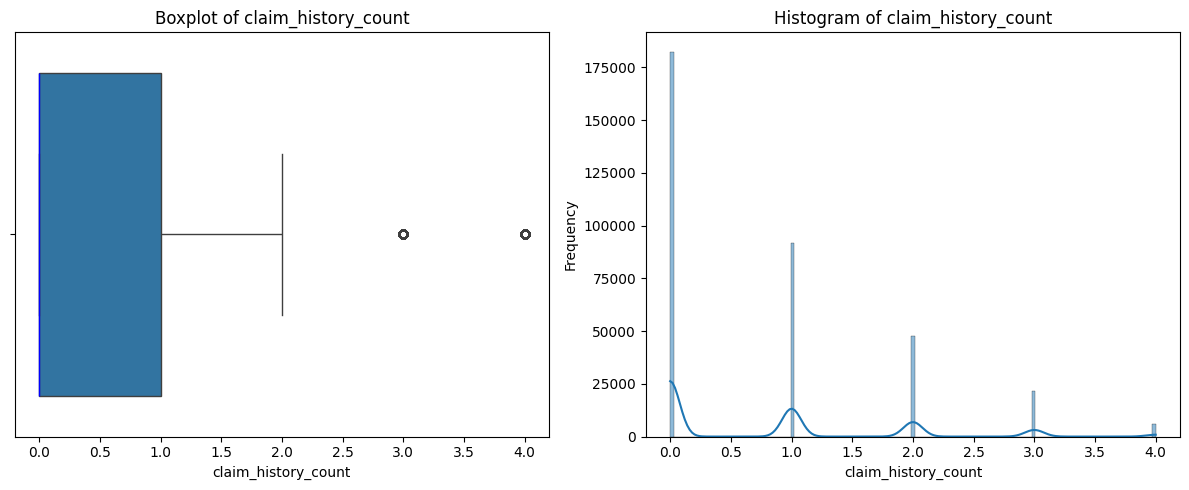

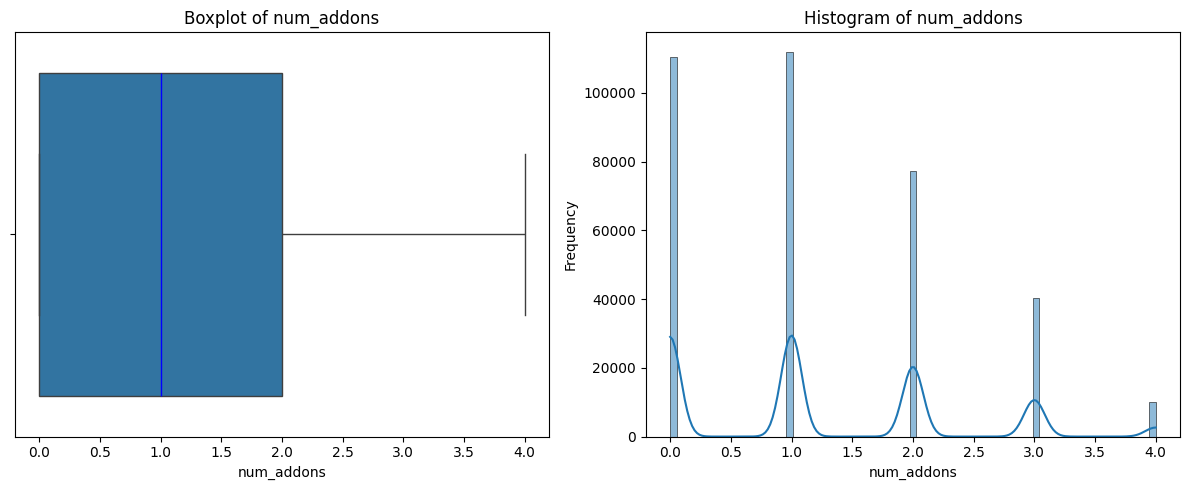

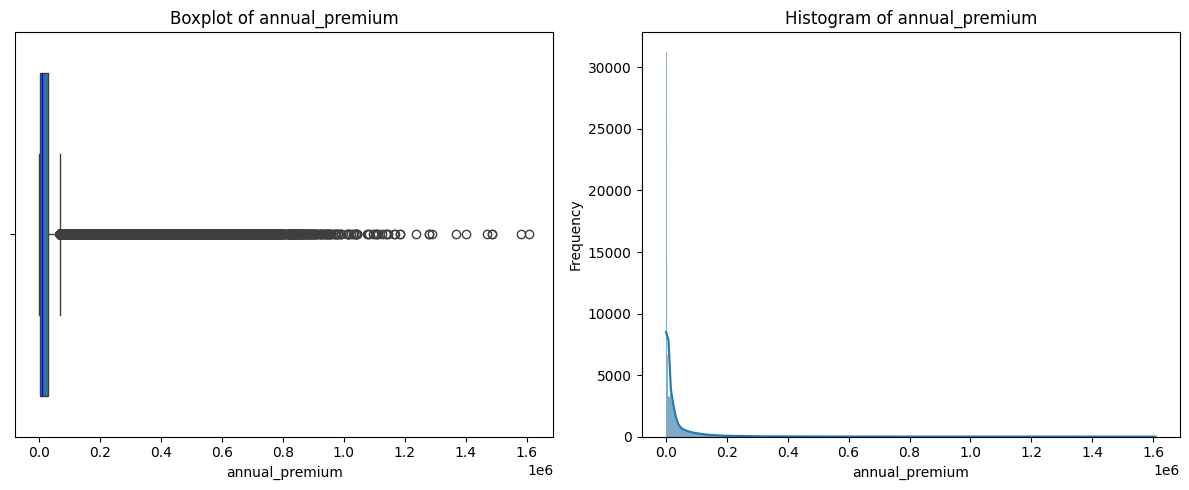

In [39]:
for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sns.boxplot(x=num_cols[col], medianprops={'color': 'blue'}, ax=axes[0])
    axes[0].set_title(f'Boxplot of {col}')
    axes[0].set_xlabel(col)

    sns.histplot(x=num_cols[col], kde=True, ax=axes[1])
    axes[1].set_title(f'Histogram of {col}')
    axes[1].set_xlabel(col)
    axes[1].set_ylabel('Frequency')

    plt.tight_layout()
    plt.show()

In [40]:
#cat_cols_ohe

In [40]:
cat_cols_ohe

,city,state,vehicle_make,vehicle_model,variant,segment,fuel_type,colour,policy_type,usage_type,vehicle_type,previous_insurer
0,Rajahmundry,Andhra Pradesh,Royal Enfield,Bullet 500,STD,retro,Petrol,Sports Blue,Comprehensive,Personal,bike,Not available
1,Indore,Madhya Pradesh,Yamaha,Fascino 125,ABS,scooter,Petrol,Yellow,Third Party,Personal,bike,Not available
2,Patna,Bihar,Suzuki,Gixxer 150,Drum,sport,Petrol,Dual Tone,Third Party,Personal,bike,Not available
3,Muzaffarpur,Bihar,Bounce,Infinity E1,ABS,ev_scooter,Electric,Matt Black,Comprehensive,Personal,bike,Not available
4,Karnal,Haryana,Honda,CB Hornet 2.0,Limited Edition,sport,Petrol,Matt Black,Own Damage,Personal,bike,Not available
...,...,...,...,...,...,...,...,...,...,...,...,...
349995,Mysuru,Karnataka,Skoda,Kushaq,Top,suv,LPG,Khaki Green,Third Party,Not available,car,Tata AIG
349996,Jammu,Jammu & Kashmir,Skoda,Superb,CVT,sedan,Diesel,Pearl Sunset Red,Comprehensive,Not available,car,Reliance General
349997,Warangal,Telangana,Kia,Sonet,CVT,suv,Diesel,Cafe White,Comprehensive,Not available,car,Acko
349998,Mangalore,Karnataka,Jeep,Meridian,DCT,suv,Diesel,Starlight,Comprehensive,Not available,car,First time buyer


In [41]:
for col in cat_cols_ohe:
    cat_cols_ohe[col]= cat_cols_ohe[col].str.lower()
    cat_cols_ohe[col]= cat_cols_ohe[col].str.strip()

In [43]:
cat_cols_ohe

,city,state,vehicle_make,vehicle_model,variant,segment,fuel_type,colour,policy_type,usage_type,vehicle_type,previous_insurer
0,rajahmundry,andhra pradesh,royal enfield,bullet 500,std,retro,petrol,sports blue,comprehensive,personal,bike,not available
1,indore,madhya pradesh,yamaha,fascino 125,abs,scooter,petrol,yellow,third party,personal,bike,not available
2,patna,bihar,suzuki,gixxer 150,drum,sport,petrol,dual tone,third party,personal,bike,not available
3,muzaffarpur,bihar,bounce,infinity e1,abs,ev_scooter,electric,matt black,comprehensive,personal,bike,not available
4,karnal,haryana,honda,cb hornet 2.0,limited edition,sport,petrol,matt black,own damage,personal,bike,not available
...,...,...,...,...,...,...,...,...,...,...,...,...
349995,mysuru,karnataka,skoda,kushaq,top,suv,lpg,khaki green,third party,not available,car,tata aig
349996,jammu,jammu & kashmir,skoda,superb,cvt,sedan,diesel,pearl sunset red,comprehensive,not available,car,reliance general
349997,warangal,telangana,kia,sonet,cvt,suv,diesel,cafe white,comprehensive,not available,car,acko
349998,mangalore,karnataka,jeep,meridian,dct,suv,diesel,starlight,comprehensive,not available,car,first time buyer


In [44]:
#cat_cols_mlb

In [42]:
addons_list= cat_cols_mlb.apply(lambda x: [item.lower() for item in x])

In [43]:
addons_list

0                                               [no addons]
1                                               [no addons]
2         [roadside assistance, consumables cover, retur...
3                                               [no addons]
4                                               [no addons]
                                ...                        
349995                                          [no addons]
349996                                    [tyre protection]
349997         [personal accident cover, consumables cover]
349998                                  [consumables cover]
349999                          [no claim bonus protection]
Name: addons_list, Length: 350000, dtype: object

In [44]:
cat_cols_ohe.columns

Index(['city', 'state', 'vehicle_make', 'vehicle_model', 'variant', 'segment',
       'fuel_type', 'colour', 'policy_type', 'usage_type', 'vehicle_type',
       'previous_insurer'],
      dtype='object')

In [45]:
cols= [ 'state', 'vehicle_make', 'variant', 'segment', 'fuel_type', 'colour', 'policy_type', 'usage_type', 'vehicle_type', 'previous_insurer']

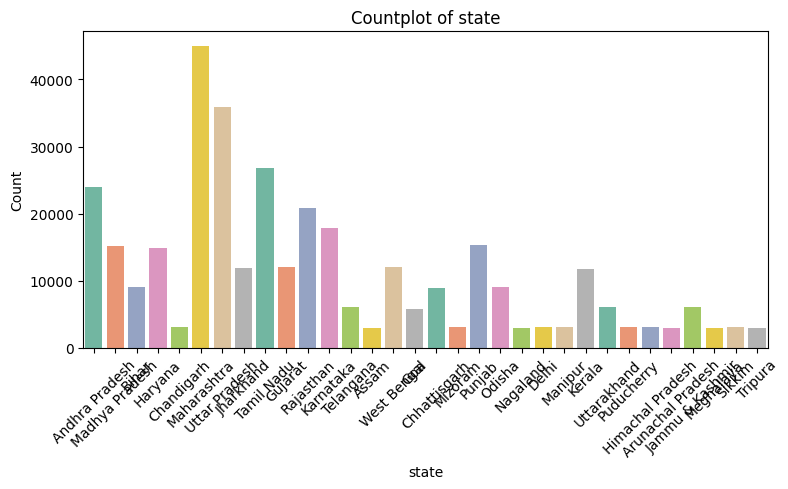

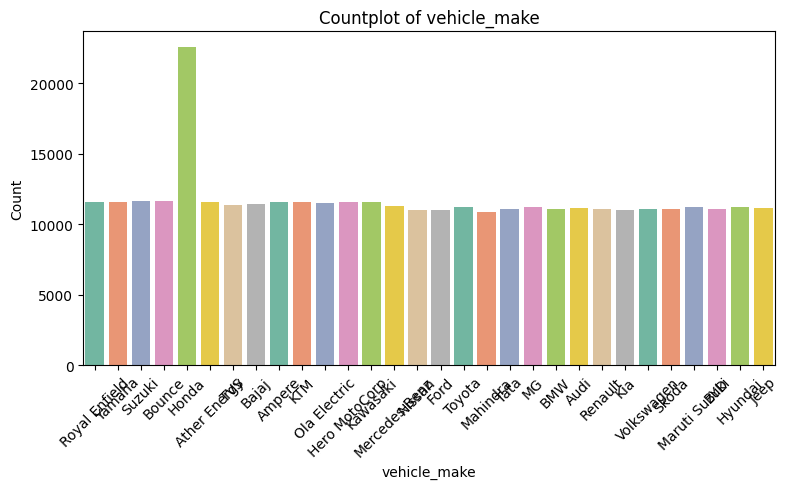

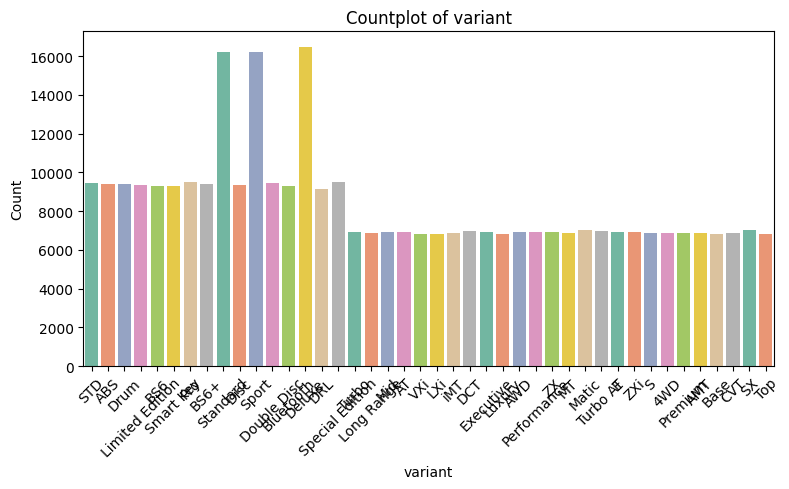

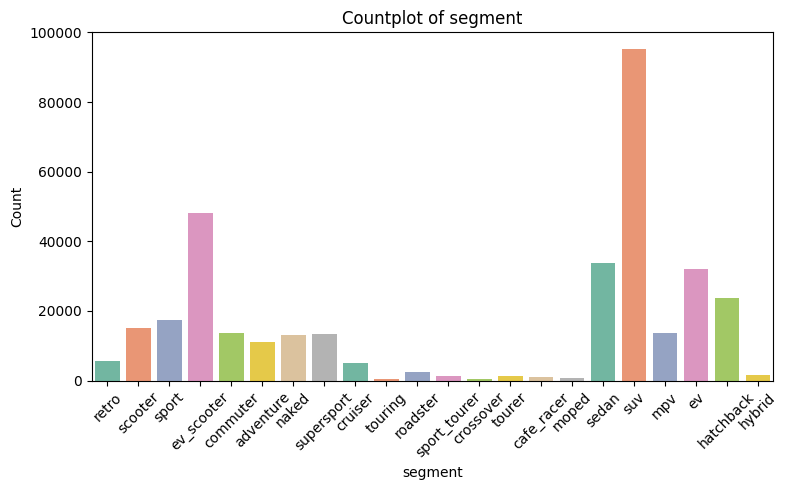

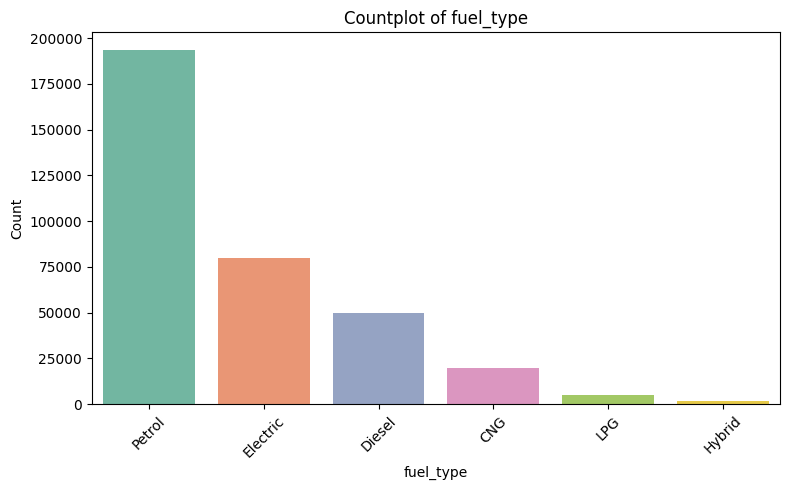

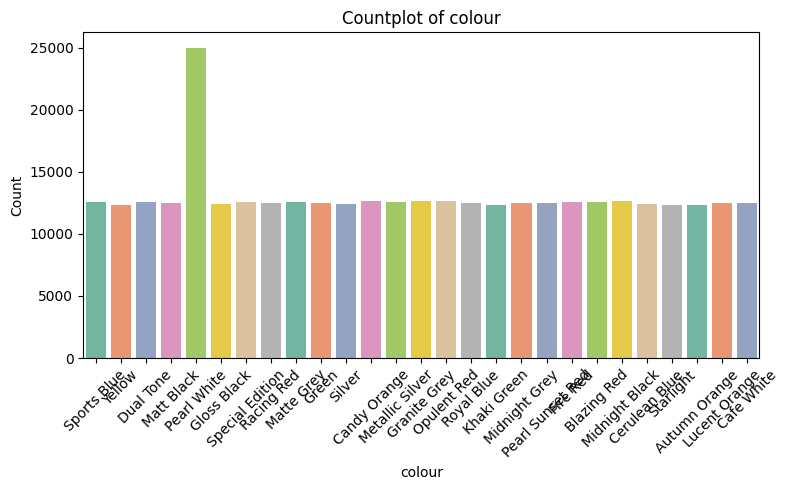

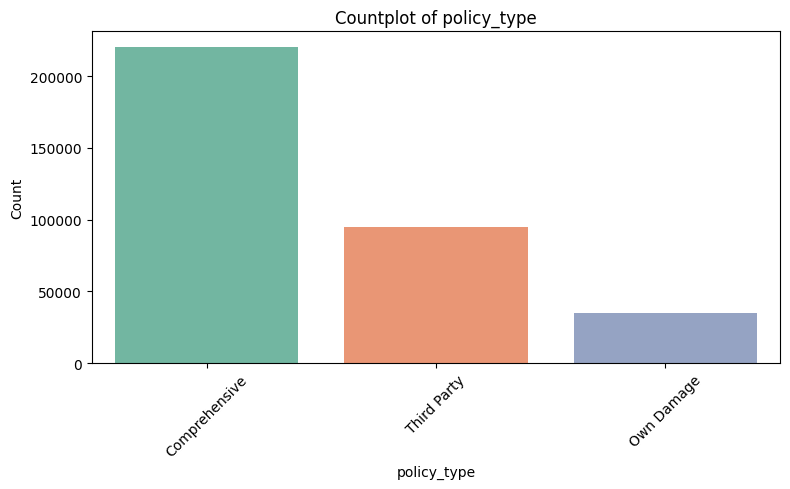

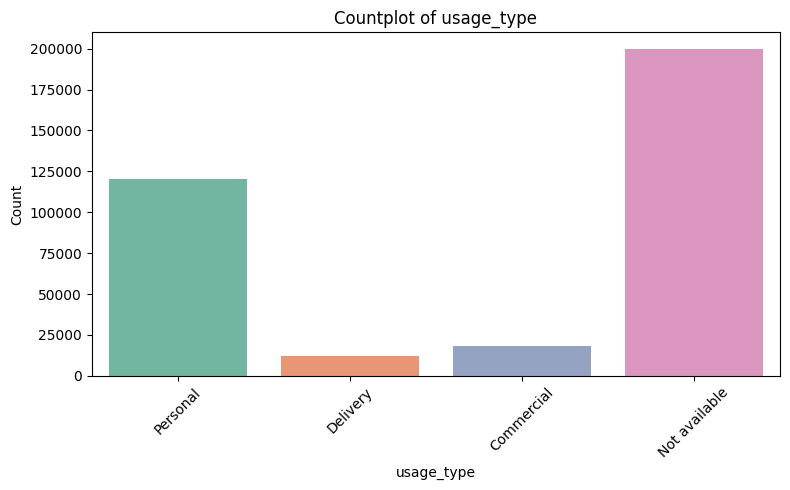

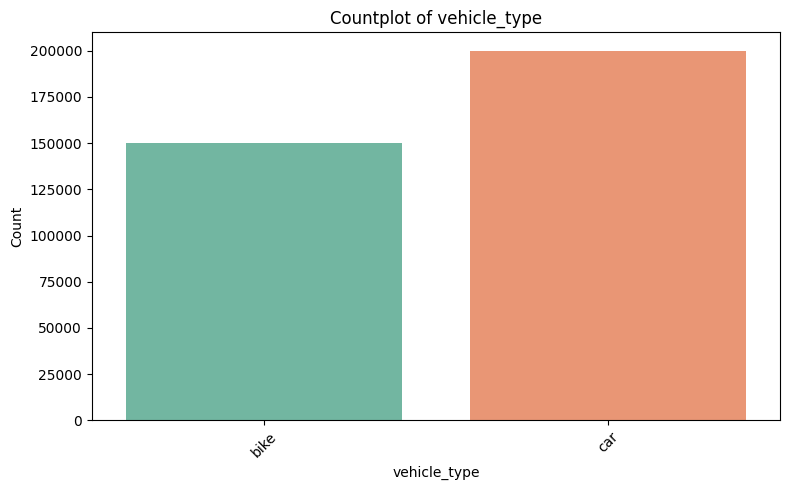

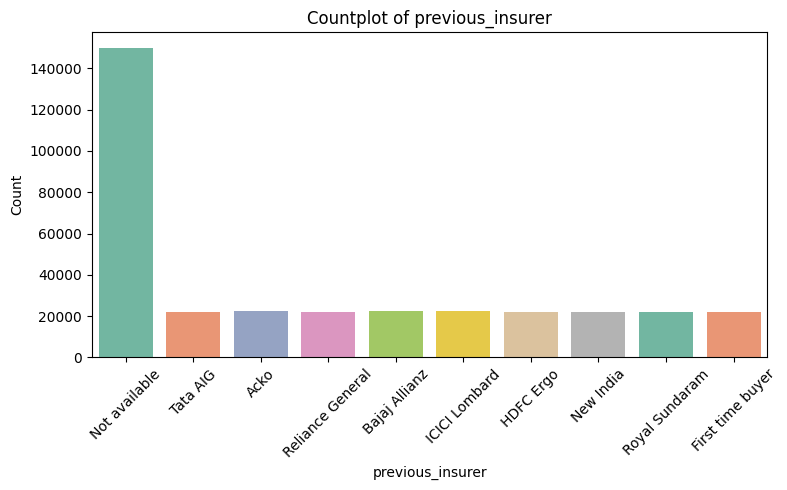

In [49]:
for col in cols:
    plt.figure(figsize=(8, 5))

    ax = sns.countplot(x=combined_df[col], palette='Set2', hue=combined_df[col])

    ax.set_title(f'Countplot of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Count')

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### Bivariate Analysis

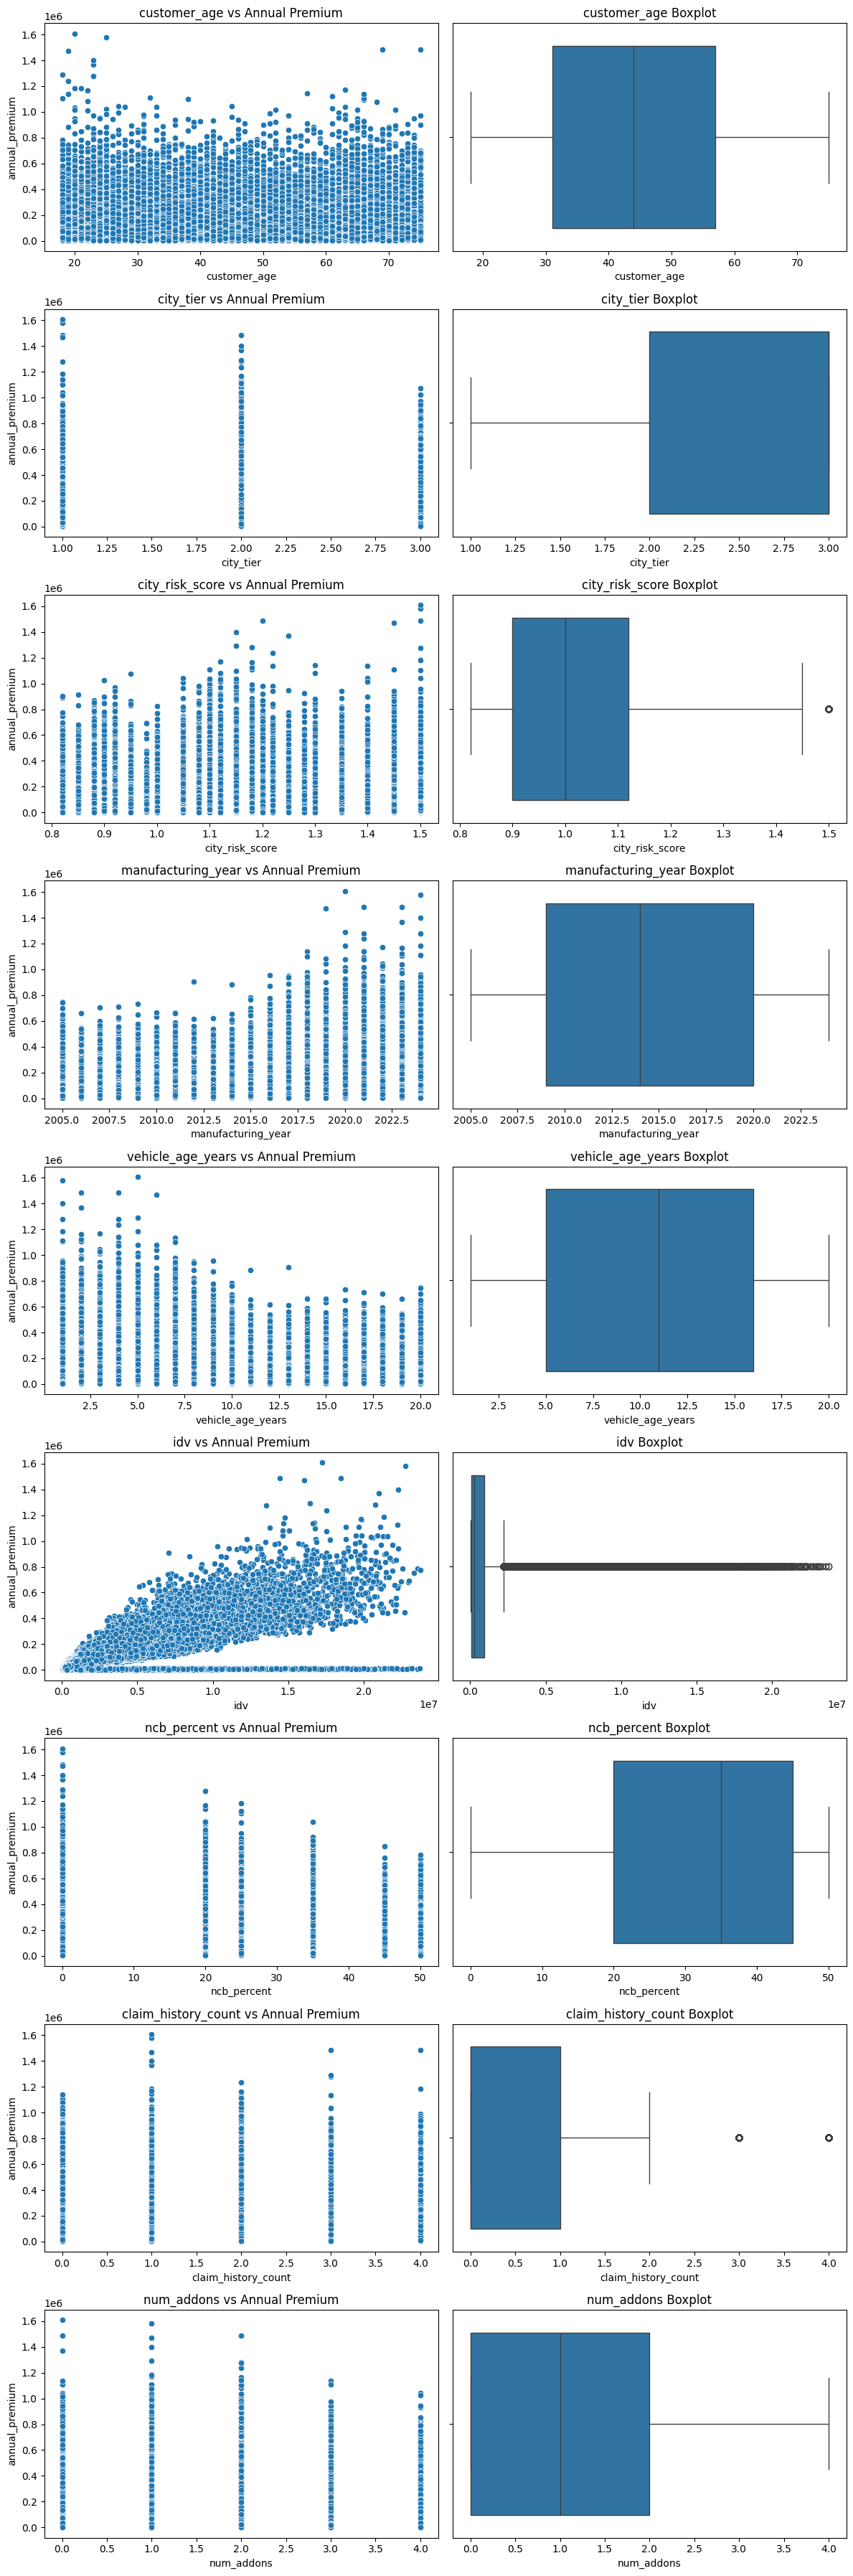

In [50]:
features = [col for col in num_cols if col != 'annual_premium']

fig, ax = plt.subplots(len(features), 2, figsize=(12, 4*len(features)))
for i, col in enumerate(features):

    # Scatterplot
    sns.scatterplot(
        x=combined_df[col],
        y=combined_df['annual_premium'],
        ax=ax[i,0]
    )

    ax[i,0].set_title(f"{col} vs {'Annual Premium'}")

    # Boxplot
    sns.boxplot(
        x=combined_df[col],
        ax=ax[i,1]
    )

    ax[i,1].set_title(f"{col} Boxplot")

plt.tight_layout()
plt.show()

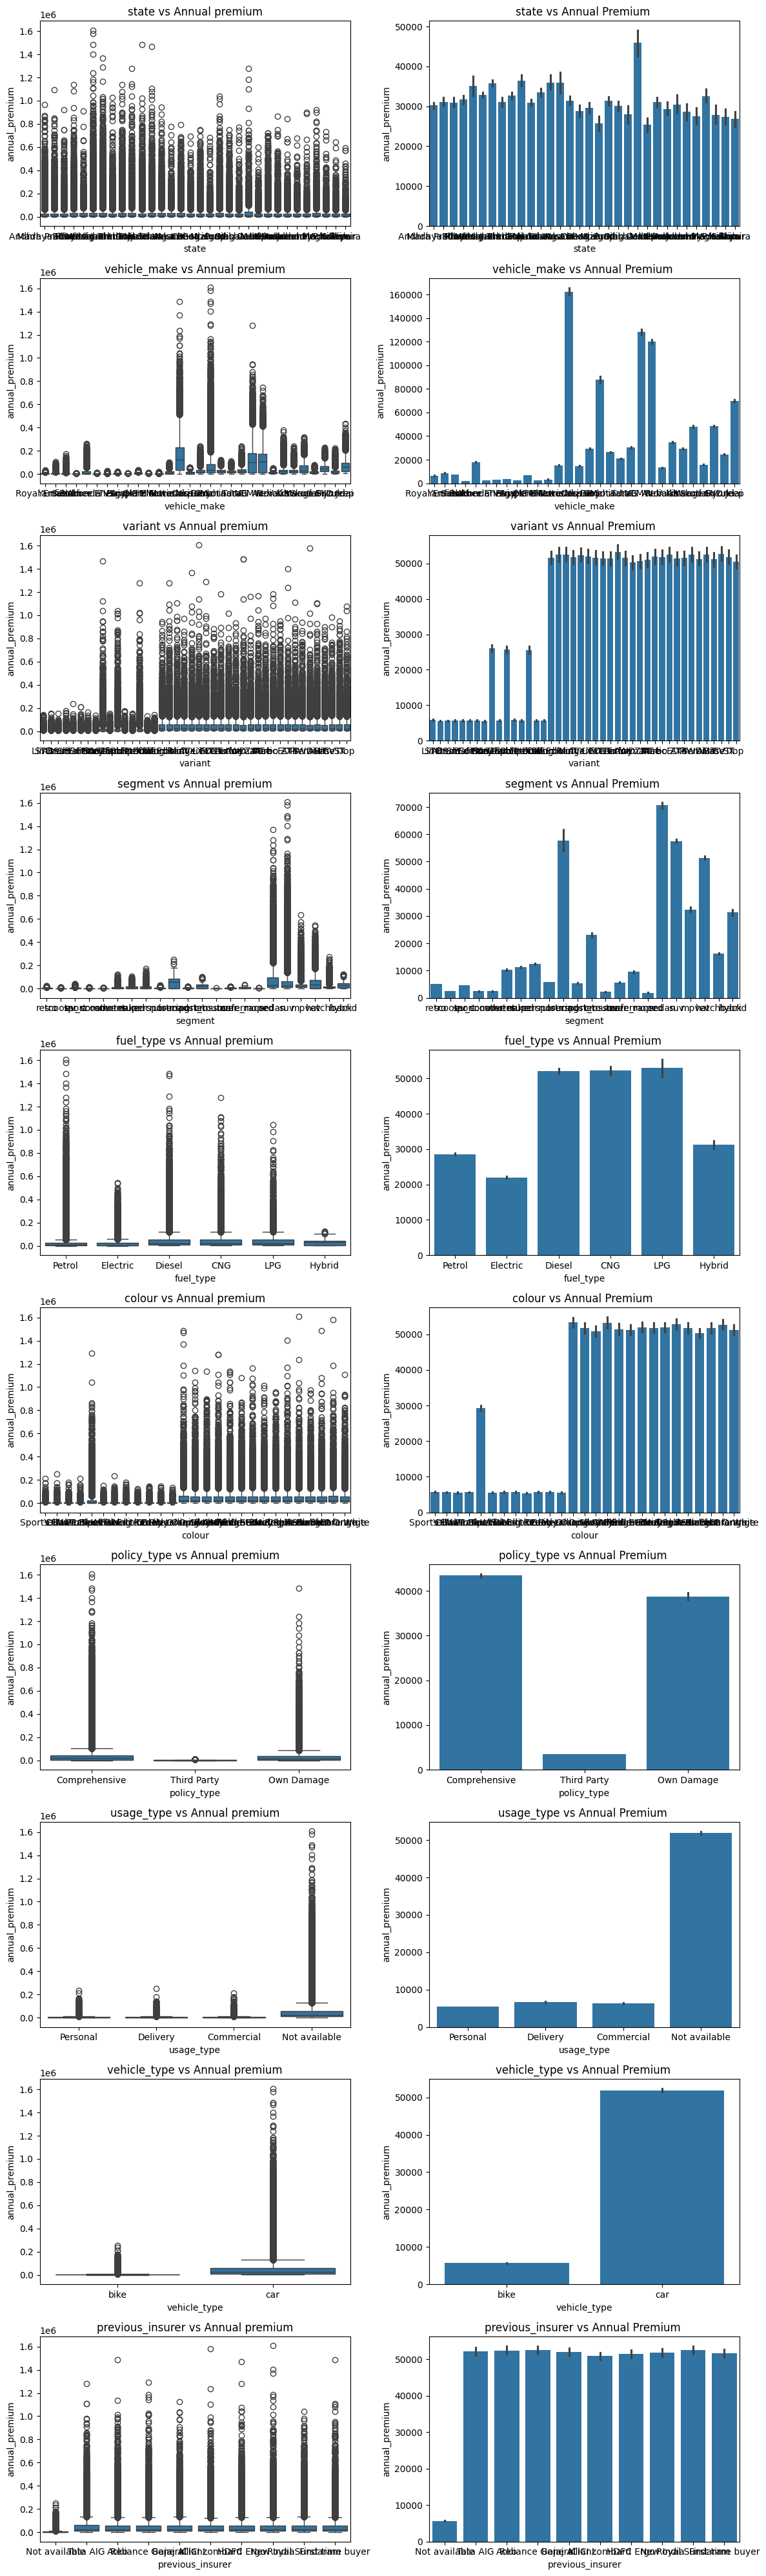

In [51]:
features = [col for col in cols if col != 'annual_premium']
fig,ax = plt.subplots(len(features), 2, figsize = (12,4*len(features)))
for i , col in enumerate(features):

    #boxplot
    sns.boxplot(x=combined_df[col], y=combined_df['annual_premium'], ax=ax[i,0])
    ax[i,0].set_title(f"{col} vs Annual premium")

    #Barchart
    sns.barplot(x=combined_df[col], y=combined_df['annual_premium'], ax=ax[i,1])
    ax[i,1].set_title(f"{col} vs Annual Premium ")
   
plt.tight_layout()
plt.show()

### Multivariate Analysis

In [52]:
corr_matrix= num_cols.corr()
corr_matrix

,customer_age,city_tier,city_risk_score,manufacturing_year,vehicle_age_years,idv,ncb_percent,claim_history_count,num_addons,annual_premium
customer_age,1.000000,0.004116,-0.004139,-0.003316,0.003316,0.061841,-0.001021,0.016830,0.038513,0.056480
city_tier,0.004116,1.000000,-0.942855,-0.001253,0.001253,0.001329,-0.003047,-0.000044,0.003476,-0.061520
city_risk_score,-0.004139,-0.942855,1.000000,0.000810,-0.000810,-0.001476,0.002404,0.000860,-0.004688,0.065705
manufacturing_year,-0.003316,-0.001253,0.000810,1.000000,-1.000000,0.212267,-0.000784,-0.000069,-0.000578,0.114713
vehicle_age_years,0.003316,0.001253,-0.000810,-1.000000,1.000000,-0.212267,0.000784,0.000069,0.000578,-0.114713
idv,0.061841,0.001329,-0.001476,0.212267,-0.212267,1.000000,0.000285,0.039846,0.094452,0.786297
ncb_percent,-0.001021,-0.003047,0.002404,-0.000784,0.000784,0.000285,1.000000,0.000380,0.000797,-0.095884
claim_history_count,0.016830,-0.000044,0.000860,-0.000069,0.000069,0.039846,0.000380,1.000000,0.024638,0.077372
num_addons,0.038513,0.003476,-0.004688,-0.000578,0.000578,0.094452,0.000797,0.024638,1.000000,0.101728
annual_premium,0.056480,-0.061520,0.065705,0.114713,-0.114713,0.786297,-0.095884,0.077372,0.101728,1.000000


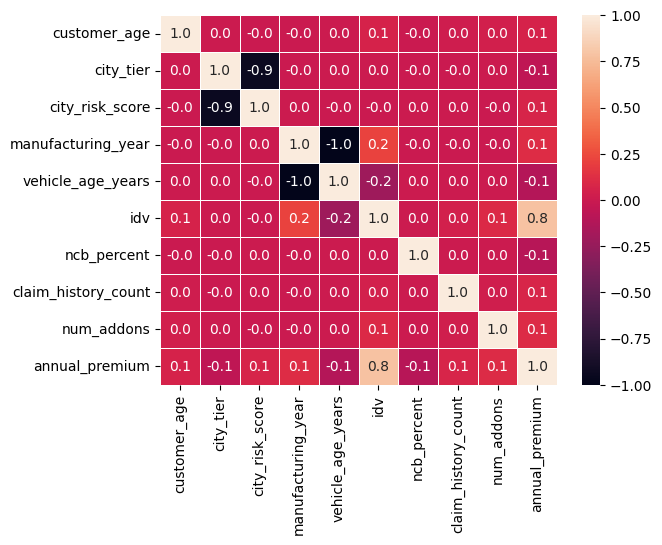

In [53]:
sns.heatmap(corr_matrix, annot=True, fmt='.1f', linewidths=0.5)
plt.show()

### Train_test_split

In [46]:
combined_df.columns

Index(['customer_age', 'city', 'state', 'city_tier', 'city_risk_score',
       'vehicle_make', 'vehicle_model', 'variant', 'segment', 'fuel_type',
       'colour', 'manufacturing_year', 'vehicle_age_years', 'idv',
       'ncb_percent', 'claim_history_count', 'policy_type', 'usage_type',
       'num_addons', 'addons_list', 'annual_premium', 'vehicle_type',
       'previous_insurer'],
      dtype='object')

In [47]:
x= combined_df.drop('annual_premium', axis=1)
y= combined_df['annual_premium']

In [48]:
from  sklearn.model_selection import train_test_split

In [49]:
x_train, x_test, y_train, y_test= train_test_split(x, y, test_size=0.2, random_state=42)
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(280000, 22) (70000, 22) (280000,) (70000,)


In [50]:
for col in ['vehicle_make', 'vehicle_model', 'variant', 'segment', 'fuel_type', 'colour', 'policy_type', 'usage_type', 'vehicle_type', 'previous_insurer', 'city', 'state', 'city_tier']:
    print(col, x_train[col].nunique())

vehicle_make 30
vehicle_model 272
variant 42
segment 22
fuel_type 6
colour 27
policy_type 3
usage_type 4
vehicle_type 2
previous_insurer 10
city 117
state 32
city_tier 3


### Encoding and Scaling

In [51]:
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, RobustScaler
from sklearn.compose import ColumnTransformer
import category_encoders as ce

In [52]:
x_train_ohe = ['fuel_type', 'policy_type', 'usage_type', 'vehicle_type', 'previous_insurer', 'city_tier']

In [53]:
x_train_target = ['vehicle_make', 'vehicle_model', 'variant', 'segment', 'colour', 'city', 'state']

In [54]:
x_train_num = ['customer_age', 'city_risk_score', 'manufacturing_year', 'idv', 'ncb_percent', 'claim_history_count', 'num_addons']

In [55]:
target_encoder = ce.TargetEncoder(cols=x_train_target)
target_encoder.fit(x_train[x_train_target], y_train)

x_train_target_encoded = target_encoder.transform(x_train[x_train_target])
x_test_target_encoded = target_encoder.transform(x_test[x_train_target])

In [56]:
mlb= MultiLabelBinarizer()

addons_encoded_train= mlb.fit_transform(x_train['addons_list'])
addons_encoded_test= mlb.transform(x_test['addons_list']) 

In [57]:
addons_encoded_train_df= pd.DataFrame(addons_encoded_train, columns= mlb.classes_, index= x_train.index)
addons_encoded_train_df

,Consumables Cover,Engine Protection,Key Replacement,No Claim Bonus Protection,No addons,Passenger Cover,Personal Accident Cover,Pillion Rider Cover,Return to Invoice,Roadside Assistance,Tyre Protection,Zero Depreciation
85212,0,1,0,0,0,0,0,0,0,0,0,0
15163,0,0,0,0,0,0,0,0,0,1,0,0
45172,0,0,0,0,1,0,0,0,0,0,0,0
198782,0,0,0,0,1,0,0,0,0,0,0,0
181843,0,0,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
119879,1,0,0,0,0,0,0,0,0,0,0,0
259178,0,0,0,0,1,0,0,0,0,0,0,0
131932,0,1,0,0,0,0,0,0,0,0,0,0
146867,0,0,0,0,1,0,0,0,0,0,0,0


In [58]:
addons_encoded_test_df= pd.DataFrame(addons_encoded_test, columns= mlb.classes_, index= x_test.index)
addons_encoded_test_df

,Consumables Cover,Engine Protection,Key Replacement,No Claim Bonus Protection,No addons,Passenger Cover,Personal Accident Cover,Pillion Rider Cover,Return to Invoice,Roadside Assistance,Tyre Protection,Zero Depreciation
66401,0,1,0,0,0,0,0,0,0,1,0,0
72319,0,0,0,0,0,0,0,1,0,0,0,1
191769,0,0,0,0,0,1,1,0,0,0,0,0
72776,0,1,0,0,0,0,0,1,0,0,0,1
291462,0,0,0,0,0,0,0,0,1,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
226264,0,0,0,0,1,0,0,0,0,0,0,0
320354,1,1,0,0,0,0,0,0,0,0,1,0
335485,0,0,0,0,0,0,0,0,0,0,0,1
250884,0,1,0,1,0,1,0,0,1,0,0,0


In [59]:
#ColumnTranformer

In [60]:
preprocessor= ColumnTransformer(
    transformers=[
        ('num', RobustScaler(), x_train_num),
        ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore'), x_train_ohe)
    ],
    remainder='drop'
)

In [62]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ohe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [63]:
x_train_preprocessed= preprocessor.fit_transform(x_train)
x_test_preprocessed= preprocessor.transform(x_test)

In [64]:
feature_names= preprocessor.get_feature_names_out()
feature_names

array(['num__customer_age', 'num__city_risk_score',
       'num__manufacturing_year', 'num__idv', 'num__ncb_percent',
       'num__claim_history_count', 'num__num_addons',
       'ohe__fuel_type_Diesel', 'ohe__fuel_type_Electric',
       'ohe__fuel_type_Hybrid', 'ohe__fuel_type_LPG',
       'ohe__fuel_type_Petrol', 'ohe__policy_type_Own Damage',
       'ohe__policy_type_Third Party', 'ohe__usage_type_Delivery',
       'ohe__usage_type_Not available', 'ohe__usage_type_Personal',
       'ohe__vehicle_type_car', 'ohe__previous_insurer_Bajaj Allianz',
       'ohe__previous_insurer_First time buyer',
       'ohe__previous_insurer_HDFC Ergo',
       'ohe__previous_insurer_ICICI Lombard',
       'ohe__previous_insurer_New India',
       'ohe__previous_insurer_Not available',
       'ohe__previous_insurer_Reliance General',
       'ohe__previous_insurer_Royal Sundaram',
       'ohe__previous_insurer_Tata AIG', 'ohe__city_tier_2',
       'ohe__city_tier_3'], dtype=object)

In [65]:
x_train_preprocessed= pd.DataFrame(x_train_preprocessed, columns=feature_names, index=x_train.index)
x_train_preprocessed

,num__customer_age,num__city_risk_score,num__manufacturing_year,num__idv,num__ncb_percent,num__claim_history_count,num__num_addons,ohe__fuel_type_Diesel,ohe__fuel_type_Electric,ohe__fuel_type_Hybrid,...,ohe__previous_insurer_First time buyer,ohe__previous_insurer_HDFC Ergo,ohe__previous_insurer_ICICI Lombard,ohe__previous_insurer_New India,ohe__previous_insurer_Not available,ohe__previous_insurer_Reliance General,ohe__previous_insurer_Royal Sundaram,ohe__previous_insurer_Tata AIG,ohe__city_tier_2,ohe__city_tier_3
85212,0.576923,0.454545,0.0,-0.207075,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
15163,-0.961538,-0.681818,-0.7,-0.292672,-1.4,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
45172,0.500000,-0.454545,1.0,0.196589,0.6,0.0,-0.5,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
198782,1.000000,0.363636,0.6,0.320106,0.4,0.0,-0.5,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
181843,-0.576923,-0.363636,-0.3,0.243195,-1.4,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119879,-0.230769,1.590909,1.0,-0.010483,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
259178,-0.500000,-0.090909,-0.6,-0.061087,-1.4,3.0,-0.5,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
131932,-0.615385,0.681818,-0.4,-0.233860,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
146867,0.230769,0.818182,0.3,-0.278788,-0.6,1.0,-0.5,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [66]:
x_test_preprocessed= pd.DataFrame(x_test_preprocessed, columns=feature_names, index=x_test.index)
x_test_preprocessed

,num__customer_age,num__city_risk_score,num__manufacturing_year,num__idv,num__ncb_percent,num__claim_history_count,num__num_addons,ohe__fuel_type_Diesel,ohe__fuel_type_Electric,ohe__fuel_type_Hybrid,...,ohe__previous_insurer_First time buyer,ohe__previous_insurer_HDFC Ergo,ohe__previous_insurer_ICICI Lombard,ohe__previous_insurer_New India,ohe__previous_insurer_Not available,ohe__previous_insurer_Reliance General,ohe__previous_insurer_Royal Sundaram,ohe__previous_insurer_Tata AIG,ohe__city_tier_2,ohe__city_tier_3
66401,-1.000000,-0.681818,0.8,-0.227990,0.6,0.0,0.5,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
72319,-1.000000,0.454545,-0.6,-0.302568,0.4,0.0,0.5,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
191769,-0.923077,1.000000,-0.1,0.033413,-0.6,0.0,0.5,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
72776,0.730769,-0.545455,0.3,-0.258266,0.4,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
291462,-0.115385,0.545455,0.2,0.837338,-0.4,1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
226264,-0.346154,0.454545,-0.2,1.653793,-0.4,0.0,-0.5,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
320354,-0.576923,-0.681818,-0.4,0.750372,0.4,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
335485,0.807692,1.363636,0.5,0.205151,-0.6,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
250884,-0.115385,-0.227273,-0.1,1.020548,-0.6,0.0,1.5,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


In [67]:
x_train_final= pd.concat([x_train_preprocessed, addons_encoded_train_df, x_train_target_encoded], axis=1)
x_test_final= pd.concat([x_test_preprocessed, addons_encoded_test_df, x_test_target_encoded], axis=1)

In [68]:
for col in x_train_final.columns:
    print(col)

num__customer_age
num__city_risk_score
num__manufacturing_year
num__idv
num__ncb_percent
num__claim_history_count
num__num_addons
ohe__fuel_type_Diesel
ohe__fuel_type_Electric
ohe__fuel_type_Hybrid
ohe__fuel_type_LPG
ohe__fuel_type_Petrol
ohe__policy_type_Own Damage
ohe__policy_type_Third Party
ohe__usage_type_Delivery
ohe__usage_type_Not available
ohe__usage_type_Personal
ohe__vehicle_type_car
ohe__previous_insurer_Bajaj Allianz
ohe__previous_insurer_First time buyer
ohe__previous_insurer_HDFC Ergo
ohe__previous_insurer_ICICI Lombard
ohe__previous_insurer_New India
ohe__previous_insurer_Not available
ohe__previous_insurer_Reliance General
ohe__previous_insurer_Royal Sundaram
ohe__previous_insurer_Tata AIG
ohe__city_tier_2
ohe__city_tier_3
Consumables Cover
Engine Protection
Key Replacement
No Claim Bonus Protection
No addons
Passenger Cover
Personal Accident Cover
Pillion Rider Cover
Return to Invoice
Roadside Assistance
Tyre Protection
Zero Depreciation
vehicle_make
vehicle_model
var

### Feature Selection

In [76]:
#correlation matrix

In [77]:
corr_matrix= x_train_final.corr()

In [78]:
corr_matrix

,num__customer_age,num__city_risk_score,num__manufacturing_year,num__idv,num__ncb_percent,num__claim_history_count,num__num_addons,ohe__fuel_type_Diesel,ohe__fuel_type_Electric,ohe__fuel_type_Hybrid,...,Roadside Assistance,Tyre Protection,Zero Depreciation,vehicle_make,vehicle_model,variant,segment,colour,city,state
num__customer_age,1.000000,-0.004209,-0.004253,0.060699,-0.000850,0.016224,0.037772,0.053861,-0.031942,0.006019,...,-0.001795,0.041673,-0.001366,0.087857,0.072312,0.144091,0.136439,0.150730,-0.004373,-0.002103
num__city_risk_score,-0.004209,1.000000,-0.000586,-0.002457,0.001451,0.000461,-0.004819,-0.003105,-0.000471,-0.003340,...,0.000902,-0.002088,-0.005837,-0.000095,-0.001682,-0.001762,-0.000334,-0.000266,0.955349,0.580311
num__manufacturing_year,-0.004253,-0.000586,1.000000,0.212442,0.000108,0.001825,-0.001219,0.002025,0.000047,0.000224,...,-0.000645,0.001057,0.002108,0.001195,-0.000943,0.000776,-0.000798,0.001172,0.000316,0.001000
num__idv,0.060699,-0.002457,0.212442,1.000000,-0.000090,0.041458,0.094460,0.123945,-0.044768,0.002606,...,-0.004340,0.105063,-0.005111,0.711281,0.880338,0.362903,0.446971,0.377065,0.002767,0.000444
num__ncb_percent,-0.000850,0.001451,0.000108,-0.000090,1.000000,0.000267,0.000647,0.002483,-0.001128,0.002059,...,-0.001053,-0.003567,0.001445,0.000975,0.000456,0.000712,0.000532,0.000099,0.001114,-0.000640
num__claim_history_count,0.016224,0.000461,0.001825,0.041458,0.000267,1.000000,0.025134,0.032387,-0.016971,0.005237,...,0.000722,0.026362,0.001584,0.057712,0.047819,0.095245,0.088507,0.097589,0.001609,0.001709
num__num_addons,0.037772,-0.004819,-0.001219,0.094460,0.000647,0.025134,1.000000,0.083533,-0.042793,0.015094,...,0.352411,0.317630,0.352584,0.133263,0.109022,0.221649,0.208875,0.230066,-0.004419,-0.000954
ohe__fuel_type_Diesel,0.053861,-0.003105,0.002025,0.123945,0.002483,0.032387,0.083533,1.000000,-0.222342,-0.026970,...,-0.007194,0.092533,-0.006591,0.197656,0.161613,0.328610,0.312393,0.340280,-0.003477,-0.001729
ohe__fuel_type_Electric,-0.031942,-0.000471,0.000047,-0.044768,-0.001128,-0.016971,-0.042793,-0.222342,1.000000,-0.035929,...,0.003679,-0.047438,0.004881,-0.136639,-0.110189,-0.174613,-0.210788,-0.183558,-0.000215,-0.000312
ohe__fuel_type_Hybrid,0.006019,-0.003340,0.000224,0.002606,0.002059,0.005237,0.015094,-0.026970,-0.035929,1.000000,...,0.000371,0.011552,-0.002519,-0.023469,-0.000842,0.052419,-0.001611,0.054985,-0.003900,-0.001293


In [79]:
# Variance Inflation Factor

In [80]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [81]:
vif_df= pd.DataFrame()

vif_df['features']= x_train_final.columns

vif_df['VIF']= [variance_inflation_factor(x_train_final.values, i)
                 for i in range(x_train_final.shape[1])]

vif_df

c:\Users\dell\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,features,VIF
0,num__customer_age,1.025192
1,num__city_risk_score,19.957258
2,num__manufacturing_year,1.258331
3,num__idv,5.677957
4,num__ncb_percent,1.000140
5,num__claim_history_count,1.010825
6,num__num_addons,inf
7,ohe__fuel_type_Diesel,3.012544
8,ohe__fuel_type_Electric,4.233491
9,ohe__fuel_type_Hybrid,1.087705


In [82]:
features_to_drop = vif_df.loc[[1, 27,28, 45,46], 'features'].tolist()

In [83]:
features_to_drop

['num__city_risk_score',
 'ohe__city_tier_2',
 'ohe__city_tier_3',
 'colour',
 'city']

In [84]:
x_train_vif= x_train_final.drop(columns= features_to_drop)

In [85]:
print(x_train_final.shape)
print(x_train_vif.shape)

(280000, 48)
(280000, 43)


In [86]:
vif_df_new = pd.DataFrame()

vif_df_new['features'] = x_train_vif.columns

vif_df_new['VIF'] = [
    variance_inflation_factor(x_train_vif.values, i)
    for i in range(x_train_vif.shape[1])
]

vif_df_new.sort_values(by='VIF', ascending=False)

c:\Users\dell\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,features,VIF
14,ohe__usage_type_Not available,inf
35,Roadside Assistance,inf
26,Consumables Cover,inf
29,No Claim Bonus Protection,inf
22,ohe__previous_insurer_Not available,inf
31,Passenger Cover,inf
32,Personal Accident Cover,inf
16,ohe__vehicle_type_car,inf
28,Key Replacement,inf
33,Pillion Rider Cover,inf


In [87]:
features_to_remove= vif_df_new.loc[[14,22], 'features'].tolist()
features_to_remove

['ohe__usage_type_Not available', 'ohe__previous_insurer_Not available']

In [88]:
x_train_vif_new=  x_train_vif.drop(columns= features_to_remove, axis=0)


In [89]:
print(x_train_final.shape)
print(x_train_vif_new.shape)

(280000, 48)
(280000, 41)


In [95]:
selected_cols = x_train_vif_new.columns.tolist()
selected_cols

['num__customer_age',
 'num__manufacturing_year',
 'num__idv',
 'num__ncb_percent',
 'num__claim_history_count',
 'num__num_addons',
 'ohe__fuel_type_Diesel',
 'ohe__fuel_type_Electric',
 'ohe__fuel_type_Hybrid',
 'ohe__fuel_type_LPG',
 'ohe__fuel_type_Petrol',
 'ohe__policy_type_Own Damage',
 'ohe__policy_type_Third Party',
 'ohe__usage_type_Delivery',
 'ohe__usage_type_Personal',
 'ohe__vehicle_type_car',
 'ohe__previous_insurer_Bajaj Allianz',
 'ohe__previous_insurer_First time buyer',
 'ohe__previous_insurer_HDFC Ergo',
 'ohe__previous_insurer_ICICI Lombard',
 'ohe__previous_insurer_New India',
 'ohe__previous_insurer_Reliance General',
 'ohe__previous_insurer_Royal Sundaram',
 'ohe__previous_insurer_Tata AIG',
 'Consumables Cover',
 'Engine Protection',
 'Key Replacement',
 'No Claim Bonus Protection',
 'No addons',
 'Passenger Cover',
 'Personal Accident Cover',
 'Pillion Rider Cover',
 'Return to Invoice',
 'Roadside Assistance',
 'Tyre Protection',
 'Zero Depreciation',
 'vehic

In [96]:
# Feature Importance

In [97]:
from sklearn.ensemble import RandomForestRegressor

In [110]:
rf= RandomForestRegressor(n_estimators=20, random_state=42, n_jobs=-1)

In [100]:
rf.fit(x_train_vif_new, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"ma

In [102]:
importance= rf.feature_importances_
importance

array([6.38541185e-03, 2.62048467e-03, 6.62581209e-01, 5.41648950e-02,
       1.04331105e-02, 1.26757840e-03, 3.42647717e-04, 4.72227084e-04,
       1.92573682e-06, 1.37274880e-04, 3.76028264e-04, 5.10695875e-04,
       2.09049699e-01, 5.07292657e-05, 2.30861938e-05, 2.80607944e-05,
       3.22984278e-04, 2.76948269e-04, 2.58977501e-04, 3.10017584e-04,
       3.18739184e-04, 3.03554128e-04, 3.51716802e-04, 3.00310835e-04,
       3.06320873e-04, 3.15799830e-04, 2.43338921e-04, 3.51467040e-04,
       2.76752002e-04, 2.68989192e-04, 2.99814795e-04, 7.27607073e-06,
       3.90710992e-04, 3.67335064e-04, 3.29593187e-04, 2.41187083e-04,
       1.09317431e-03, 2.98808958e-02, 2.81538772e-03, 1.22678482e-03,
       1.06968599e-02])

In [104]:
feature_importance= pd.DataFrame({'Feature': x_train_vif_new.columns, 
                                  'Importance': importance})
feature_importance

,Feature,Importance
0,num__customer_age,0.006385
1,num__manufacturing_year,0.002620
2,num__idv,0.662581
3,num__ncb_percent,0.054165
4,num__claim_history_count,0.010433
5,num__num_addons,0.001268
6,ohe__fuel_type_Diesel,0.000343
7,ohe__fuel_type_Electric,0.000472
8,ohe__fuel_type_Hybrid,0.000002
9,ohe__fuel_type_LPG,0.000137


In [105]:
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
2,num__idv,0.662581
12,ohe__policy_type_Third Party,0.209050
3,num__ncb_percent,0.054165
37,vehicle_model,0.029881
40,state,0.010697
4,num__claim_history_count,0.010433
0,num__customer_age,0.006385
38,variant,0.002815
1,num__manufacturing_year,0.002620
5,num__num_addons,0.001268


In [108]:
top20_features = feature_importance.head(20)['Feature'].tolist()

x_train_top20 = x_train_vif_new[top20_features]
x_train_top20

,num__idv,ohe__policy_type_Third Party,num__ncb_percent,vehicle_model,state,num__claim_history_count,num__customer_age,variant,num__manufacturing_year,num__num_addons,segment,vehicle_make,ohe__policy_type_Own Damage,ohe__fuel_type_Electric,Return to Invoice,ohe__fuel_type_Petrol,Roadside Assistance,ohe__previous_insurer_Royal Sundaram,No Claim Bonus Protection,ohe__fuel_type_Diesel
85212,-0.207075,1.0,0.0,9517.304913,32943.224332,0.0,0.576923,5742.727498,0.0,0.0,9517.304913,6602.789587,0.0,0.0,0,1.0,0,0.0,0,0.0
15163,-0.292672,0.0,-1.4,2499.567422,30007.878318,0.0,-0.961538,5699.207217,-0.7,0.0,2392.150324,2359.738731,0.0,1.0,0,0.0,1,0.0,0,0.0
45172,0.196589,0.0,0.6,11127.211196,32786.248674,0.0,0.500000,5620.704102,1.0,-0.5,11312.483353,15367.894244,1.0,0.0,0,1.0,0,0.0,0,0.0
198782,0.320106,0.0,0.4,16541.900892,30857.423539,0.0,1.000000,51332.902916,0.6,-0.5,57496.852797,35037.676538,0.0,0.0,0,1.0,0,1.0,0,0.0
181843,0.243195,0.0,-1.4,26120.768533,28011.818754,1.0,-0.576923,51782.078119,-0.3,0.0,51478.259497,20854.502481,1.0,1.0,0,0.0,0,0.0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119879,-0.010483,1.0,0.0,8751.213668,35400.243967,1.0,-0.230769,5612.976642,1.0,0.0,11312.483353,6970.646142,0.0,0.0,0,1.0,0,0.0,0,0.0
259178,-0.061087,1.0,-1.4,15567.944523,30794.685496,3.0,-0.500000,26269.096653,-0.6,-0.5,16244.547827,20854.502481,0.0,0.0,0,1.0,0,0.0,0,0.0
131932,-0.233860,1.0,0.0,7010.594480,30987.714368,0.0,-0.615385,5565.990354,-0.4,0.0,12361.810059,3020.845204,0.0,0.0,0,1.0,0,0.0,0,0.0
146867,-0.278788,0.0,-0.6,2499.567422,35550.079488,1.0,0.230769,5742.727498,0.3,-0.5,2392.150324,2359.738731,0.0,1.0,0,0.0,0,0.0,0,0.0


In [121]:
selected_feature_importance_cols= feature_importance['Feature'].tolist()
selected_feature_importance_cols

['num__idv',
 'ohe__policy_type_Third Party',
 'num__ncb_percent',
 'vehicle_model',
 'state',
 'num__claim_history_count',
 'num__customer_age',
 'variant',
 'num__manufacturing_year',
 'num__num_addons',
 'segment',
 'vehicle_make',
 'ohe__policy_type_Own Damage',
 'ohe__fuel_type_Electric',
 'Return to Invoice',
 'ohe__fuel_type_Petrol',
 'Roadside Assistance',
 'ohe__previous_insurer_Royal Sundaram',
 'No Claim Bonus Protection',
 'ohe__fuel_type_Diesel',
 'Tyre Protection',
 'ohe__previous_insurer_Bajaj Allianz',
 'ohe__previous_insurer_New India',
 'Engine Protection',
 'ohe__previous_insurer_ICICI Lombard',
 'Consumables Cover',
 'ohe__previous_insurer_Reliance General',
 'ohe__previous_insurer_Tata AIG',
 'Personal Accident Cover',
 'ohe__previous_insurer_First time buyer',
 'No addons',
 'Passenger Cover',
 'ohe__previous_insurer_HDFC Ergo',
 'Key Replacement',
 'Zero Depreciation',
 'ohe__fuel_type_LPG',
 'ohe__usage_type_Delivery',
 'ohe__vehicle_type_car',
 'ohe__usage_type

In [1]:
# Saving the files

In [125]:
x_train_final.to_csv(r'C:\projects\acko_insurance_ai_platform\data\processed\x_train_final.csv', index=False)
x_test_final.to_csv(r'C:\projects\acko_insurance_ai_platform\data\processed\x_test_final.csv', index=False)
y_train.to_csv(r'C:\projects\acko_insurance_ai_platform\data\processed\y_train_final.csv', index=False)
y_test.to_csv(r'C:\projects\acko_insurance_ai_platform\data\processed\y_test_final.csv', index=False)
feature_importance.to_csv(r'C:\projects\acko_insurance_ai_platform\data\processed\module2_feature_importance.csv', index=False)

In [3]:
import joblib

In [2]:
# Saving the Encoding and Scaling files 

In [69]:
joblib.dump(preprocessor, r'C:\projects\acko_insurance_ai_platform\models\preprocessor.pkl')       
joblib.dump(target_encoder, r'C:\projects\acko_insurance_ai_platform\models\target_encoder.pkl')  
joblib.dump(mlb, r'C:\projects\acko_insurance_ai_platform\models\mlb_addons.pkl')                  

['C:\\projects\\acko_insurance_ai_platform\\models\\mlb_addons.pkl']